# 03 - phase 2: multiple leaks

phase 1 works: one leak, regress one position. obvious next step: scenes with **1 to 3 leaks**. that changes the nature of the problem tho, because the answer is now a *set* of positions of unknown size. a network with a fixed output can't just "regress the positions": which output belongs to which leak, and what should the unused outputs do?

the encoder stays exactly the same as in phase 1 (attention over sensors, then over time, one 100-d vector per scene). only the head on top of it and the loss change:

| | idea | output | loss |
|---|---|---|---|
| A | slots + soft permutation | 3 slots of (confidence, x, y) | sinkhorn matching with penalties for missed / hallucinated leaks |
| B1 | heatmap from parametric blobs | 5 gaussians (strength, mean, covariance) | RMSE to a target heatmap |
| B2 | heatmap from a conv decoder | 64x64 map | class-weighted RMSE to the target heatmap |
| B3 | heatmap straight from a linear layer | 32x32 map | RMSE (sanity check) |
| C | just count the leaks | one number | abs. difference (sanity check) |

going through them in that order, including the small numpy prototypes that I build first to convince myself that a building block does what I think it does. all trainings come from `scripts/train.py` and are only loaded here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize
import scipy.special
import torch
from torch.utils.data import default_collate

from leaknet import losses, plotting
from leaknet.data import load_scenes
from leaknet.train import EXPERIMENTS, load_run, predict, train_valid_split

RESULTS = "../results"
device = "cuda:0" if torch.cuda.is_available() else "cpu"
rng = np.random.default_rng(0)


def scenes_of(name, seed=0):
    """the (train, valid) scenes that an experiment was run on"""
    config = EXPERIMENTS[name]
    data = load_scenes(f"../data/{config['data_file']}", config["n_samples"])
    ds_tra, ds_val = train_valid_split(data, config["train_fraction"], seed=seed)
    return [ds_tra[i] for i in range(len(ds_tra))], [ds_val[i] for i in range(len(ds_val))]


def show_matrix(ax, mtx, title):
    ax.imshow(mtx, cmap="Greens", vmin=0, vmax=max(1, mtx.max()))
    for (i, j), value in np.ndenumerate(mtx):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
    ax.set(xticks=[], yticks=[])
    ax.set_title(title, fontsize=10, color="dimgray")

## A. slots + soft permutation

the network outputs 3 slots, each with a confidence and a position. to compute a loss, the slots have to be assigned to the true leaks first. the classic way is hungarian matching, but that is a hard, non-differentiable decision. I want the assignment itself to be soft, so that it can depend on the predicted confidences and gradients can flow through it.

### prototype: hungarian matching vs. sinkhorn

sinkhorn normalization turns a cost matrix into a (nearly) doubly stochastic matrix by alternately normalizing rows and columns in log space. low temperature -> converges to the hungarian solution, higher temperature -> stays soft.

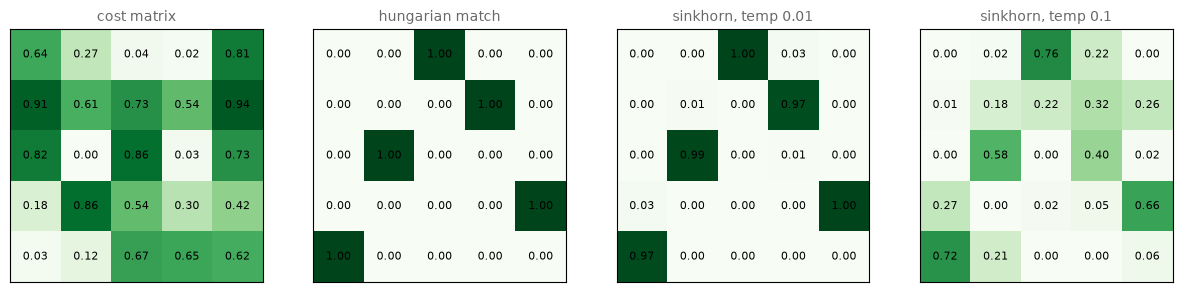

In [2]:
def hungarian_matching(mtx_cost):
    indices = scipy.optimize.linear_sum_assignment(mtx_cost)
    permutation = np.zeros(mtx_cost.shape)
    permutation[indices] = 1
    return permutation


def sinkhorn(mtx_cost, temp=0.01, n_iter=20):
    # numpy wrapper around the torch version that the loss uses
    return losses.my_sinkhorn_norm(torch.tensor(mtx_cost), temp, n_iter).numpy()


cost = rng.random((5, 5))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
show_matrix(axes[0], cost, "cost matrix")
show_matrix(axes[1], hungarian_matching(cost), "hungarian match")
show_matrix(axes[2], sinkhorn(cost, temp=0.01), "sinkhorn, temp 0.01")
show_matrix(axes[3], sinkhorn(cost, temp=0.1), "sinkhorn, temp 0.1")

### prototype: a cost matrix that knows about confidence and padding

scenes have 1 to 3 leaks, so the label is padded to 3 entries with a mask. rows = predicted slots, columns = label entries:

- for a **confident** slot the cost of a real leak is the distance to it, padding entries are free
- for an **unconfident** slot real leaks are expensive (a "soft maximum" of all distances), padding entries are free

-> confident slots should end up on the nearest real leaks and unconfident ones on the padding. below: 3 real leaks + 2 padding entries, 5 slots with random confidences.

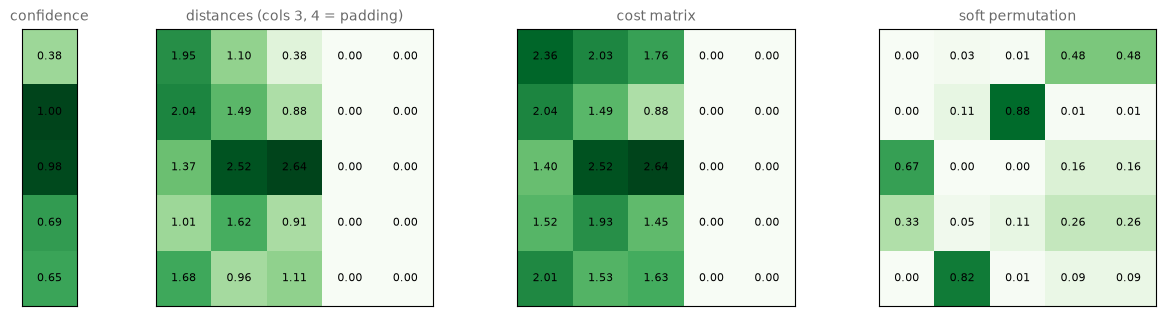

In [3]:
test_label = np.array([1, 1, 1, 0, 0])[None, :]  # 1 = real leak (note: this is the inverse of the mask in the dataset)
test_conf = rng.random((5, 1))
test_euclid = np.zeros((5, 5))
test_euclid[:, 0:3] = rng.random((5, 3)) * (2 * np.sqrt(2))

temp = 0.1
pseudomax = scipy.special.softmax(test_euclid.reshape(-1) / temp)
pseudomax = np.sum(pseudomax.reshape(test_euclid.shape) * test_euclid)

test_mtx = (test_conf * test_euclid) + pseudomax * ((1 - test_conf) * np.ones(test_euclid.shape) * test_label)
permutation = sinkhorn(test_mtx, temp=0.1, n_iter=100)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[0.25, 1, 1, 1]))
show_matrix(axes[0], test_conf, "confidence")
show_matrix(axes[1], test_euclid, "distances (cols 3, 4 = padding)")
show_matrix(axes[2], test_mtx, "cost matrix")
show_matrix(axes[3], permutation, "soft permutation")

two more checks:

- **edge cases:** an all-zero cost matrix gives a uniform permutation (no NaNs).
- **scale of the penalties:** what does it cost to miss a leak? I use the expected distance between two random points as the price of a false negative / false positive. in the `[-1, 1]` box that is about 1.04 (measured below). careful: the constant in the loss is the closed form for a *unit* square (0.52), so the penalties are currently half of what they should be!

In [4]:
print("sinkhorn of all-zero costs:\n", sinkhorn(np.zeros((3, 3)), temp=0.1, n_iter=100))

points_a, points_b = 2 * rng.random((1_000_000, 2)) - 1, 2 * rng.random((1_000_000, 2)) - 1
print(f"\naverage distance of two random points in [-1, 1]^2: {np.linalg.norm(points_a - points_b, axis=1).mean():.4f}")
print(f"closed form for the unit square (used in the loss): {(2 + np.sqrt(2) + 5 * np.log(np.sqrt(2) + 1)) / 15:.4f}")

sinkhorn of all-zero costs:
 [[0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]]

average distance of two random points in [-1, 1]^2: 1.0428
closed form for the unit square (used in the loss): 0.5214


a variant with explicit row / column marginals, where all surplus slots can be dumped into one "no leak" column instead of padding the labels. works nicely in isolation, but not used in the loss yet.

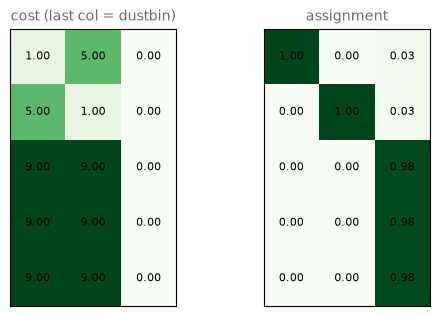

In [5]:
def sinkhorn_log_normalization(mtx_cost, row_marginal, col_marginal, temp=0.2, n_iter=20):
    """Sinkhorn normalization in log-space with custom row and column marginals."""
    assert np.isclose(np.sum(row_marginal), np.sum(col_marginal)), "Marginals must sum to the same value"
    log_kernel = -mtx_cost / temp
    for _ in range(n_iter):
        log_kernel = log_kernel - scipy.special.logsumexp(log_kernel, axis=1, keepdims=True) + np.log(row_marginal)[:, None]
        log_kernel = log_kernel - scipy.special.logsumexp(log_kernel, axis=0, keepdims=True) + np.log(col_marginal)[None, :]
    return np.exp(log_kernel)


# 5 slots, 2 real leaks and one dustbin column that has to take up 3 slots
cost_mtx = np.array([[1, 5, 0], [5, 1, 0], [9, 9, 0], [9, 9, 0], [9, 9, 0]])
perm = sinkhorn_log_normalization(cost_mtx, row_marginal=np.ones(5), col_marginal=np.array([1, 1, 3]))

fig, axes = plt.subplots(1, 2, figsize=(6, 3.6))
show_matrix(axes[0], cost_mtx, "cost (last col = dustbin)")
show_matrix(axes[1], perm, "assignment")

### training

the full loss (`losses.matching_loss`) is `2 * TP + 1 * FN + 2 * FP`, all weighted with the soft permutation:

- **TP**: distance between slots and the leaks they are assigned to
- **FN**: unconfident slots that are assigned to real leaks
- **FP**: confident slots that are assigned to padding

trained on 50k scenes with 1-3 leaks (45k / 5k), again with the batch size schedule. the three parts are logged as auxiliary curves.

best validation loss: 0.7735
parts at the end of training:  TP 0.141 | FN 0.059 | FP 0.204


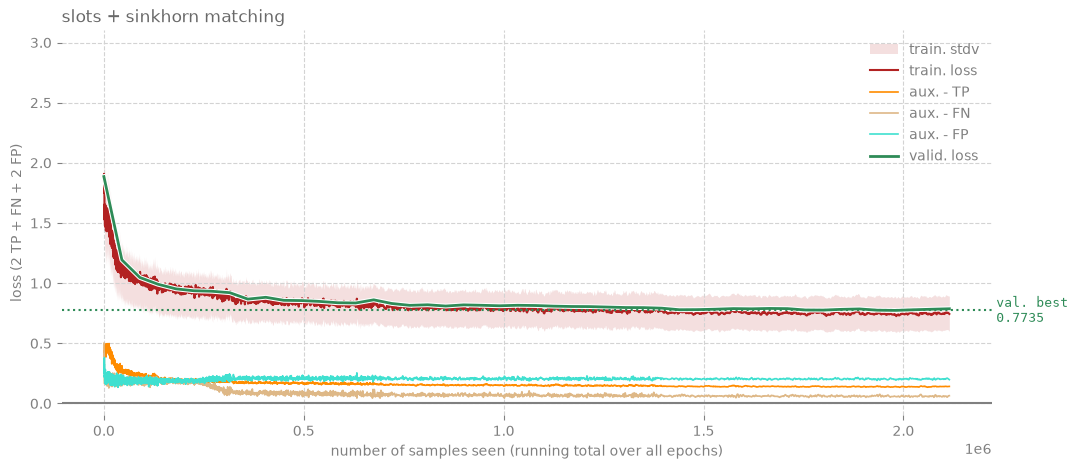

In [6]:
model_sink, history_sink = load_run("sinkhorn", RESULTS)

fig, ax = plt.subplots(figsize=(12, 5))
plotting.plot_history(history_sink, ax=ax, title="slots + sinkhorn matching", y_range=(-0.1, 3.1), y_label="loss (2 TP + FN + 2 FP)", smooth=5)

final = np.mean(history_sink["train"]["aux"][-20:], axis=0)
print(f"best validation loss: {history_sink['valid_best']:.4f}")
print(f"parts at the end of training:  TP {final[0]:.3f} | FN {final[1]:.3f} | FP {final[2]:.3f}")

### what did it learn?

the loss alone doesn't say much, so here is a hard evaluation on the validation scenes: a slot counts as a predicted leak if its confidence is above 0.5, and the predicted leaks are matched to the true ones with hungarian matching.

number of leaks correct:                0.495
mean distance of matched confident slots: 0.1349 | median 0.1057
(phase 1, one leak, for comparison: ~0.05. Predicting the center: ~0.43)

1 leak(s): mean confidence logit per slot [-16.2  14.1  13.1] | share confident [0. 1. 1.] | distance of the two always-on slots to their nearest leak 0.060, 0.089
2 leak(s): mean confidence logit per slot [-10.   13.3  12.7] | share confident [0.11 1.   1.  ] | distance of the two always-on slots to their nearest leak 0.081, 0.157
3 leak(s): mean confidence logit per slot [ 2.3 13.8 13.7] | share confident [0.62 1.   1.  ] | distance of the two always-on slots to their nearest leak 0.087, 0.163


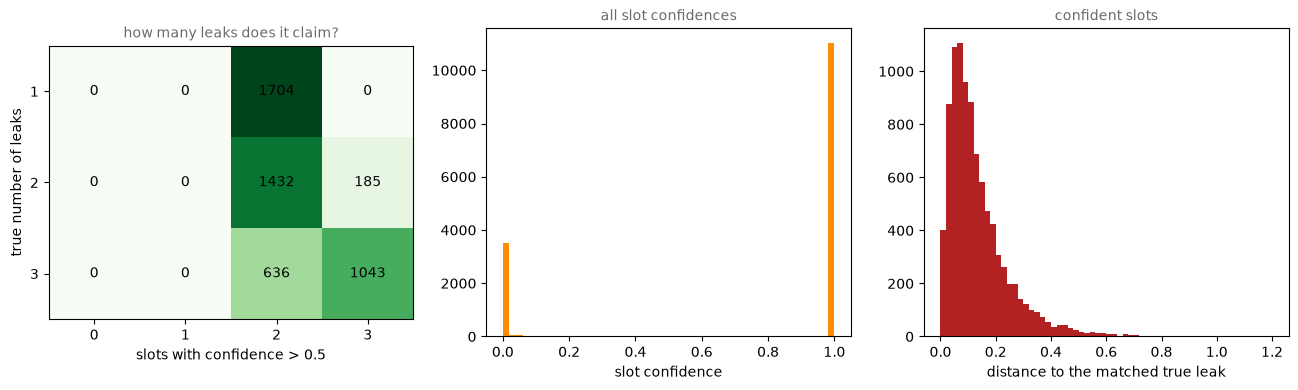

In [7]:
_, valid = scenes_of("sinkhorn")
out = predict(model_sink, valid, device)
conf, pos = torch.sigmoid(out[:, :, 0]).numpy(), out[:, :, 1:].numpy()

n_true = np.array([int(el["n_leaks"]) for el in valid])
n_pred = (conf > 0.5).sum(axis=1)

# matched distances: confident slots vs. true leaks
matched = []
for el, c, p in zip(valid, conf, pos):
    leaks, slots = el["pos_leaks"][: int(el["n_leaks"])], p[c > 0.5]
    if len(slots):
        dist = np.linalg.norm(slots[:, None, :] - leaks[None, :, :], axis=2)
        matched.extend(dist[scipy.optimize.linear_sum_assignment(dist)])
matched = np.array(matched)

confusion = np.array([[np.sum((n_true == t) & (n_pred == p)) for p in range(4)] for t in range(1, 4)])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(confusion, cmap="Greens")
for (i, j), value in np.ndenumerate(confusion):
    axes[0].text(j, i, value, ha="center", va="center")
axes[0].set(xlabel="slots with confidence > 0.5", ylabel="true number of leaks", xticks=range(4), yticks=range(3), yticklabels=[1, 2, 3])
axes[0].set_title("how many leaks does it claim?", fontsize=10, color="dimgray")
axes[1].hist(conf.reshape(-1), bins=50, color="darkorange")
axes[1].set(xlabel="slot confidence")
axes[1].set_title("all slot confidences", fontsize=10, color="dimgray")
axes[2].hist(matched, bins=60, range=(0, 1.2), color="firebrick")
axes[2].set(xlabel="distance to the matched true leak")
axes[2].set_title("confident slots", fontsize=10, color="dimgray")

print(f"number of leaks correct:                {np.mean(n_true == n_pred):.3f}")
print(f"mean distance of matched confident slots: {matched.mean():.4f} | median {np.median(matched):.4f}")
print(f"(phase 1, one leak, for comparison: ~0.05. Predicting the center: ~0.43)\n")

logit = out[:, :, 0].numpy()
for n in (1, 2, 3):
    sel = n_true == n
    dists = [np.sort(np.linalg.norm(p[c > 0.5] - el["pos_leaks"][:n][:, None], axis=2).min(axis=0)) for el, c, p in zip(valid, conf, pos) if int(el["n_leaks"]) == n]
    print(f"{n} leak(s): mean confidence logit per slot {logit[sel].mean(axis=0).round(1)} | share confident {(conf[sel] > 0.5).mean(axis=0).round(2)} | distance of the two always-on slots to their nearest leak {np.mean([d[0] for d in dists]):.3f}, {np.mean([d[1] for d in dists]):.3f}")

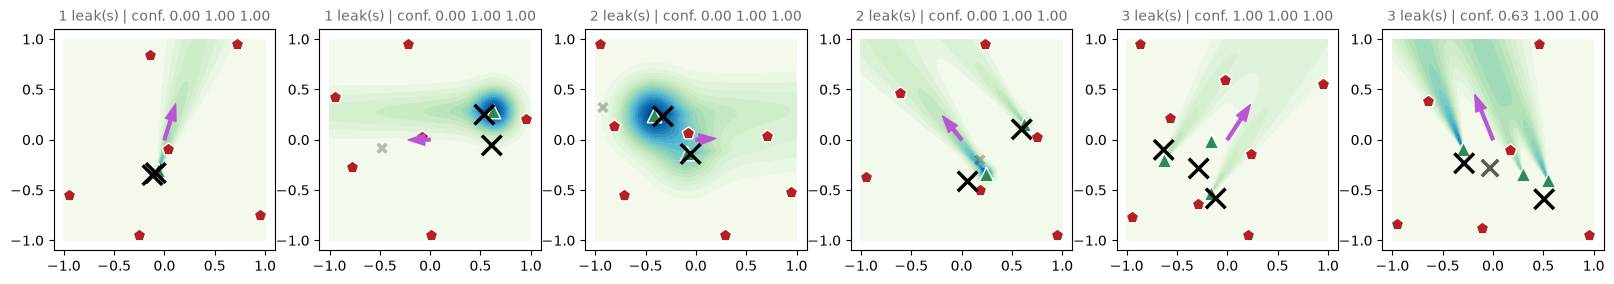

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3.7))
for ax, idx in zip(axes, [np.flatnonzero(n_true == n)[k] for n in (1, 2, 3) for k in (0, 1)]):
    el = valid[idx]
    t = int(np.argmax(el["con_sensors"].clip(0).sum(axis=1)))
    plotting.plot_scene(el, t=t, ax=ax, show_sources=False, title=f"{int(el['n_leaks'])} leak(s) | conf. " + " ".join(f"{c:.2f}" for c in conf[idx]))
    # slots: size and opacity ~ confidence
    ax.scatter(*pos[idx].T, s=40 + 160 * conf[idx], marker="x", color="black", lw=2.5, alpha=np.clip(conf[idx], 0.25, 1), zorder=4)

**it half works.** positions are fine, confidences are not.

- the **positions** are reasonable: confident slots are on average 0.13 away from their matched leak (0.06 in scenes with one leak, 0.13 with two, 0.17 with three). worse than the 0.05 of phase 1, but far from "predict the center" (0.43), and the slots don't collapse onto the mean of the leaks, which is what I was afraid the soft assignment would do.
- the **confidences** are binary and mostly constant. two of the three slots are *always* on, with logits around +13 no matter what the scene looks like. only the remaining slot reacts to the input: it stays off for one leak and switches on in 62% of the scenes with three leaks.
- so the model **never says "one leak"**! in a scene with a single leak it puts both always-on slots onto that leak (second row of numbers: 0.06 and 0.09 away from it) and pays the false positive penalty every time. that is the FP curve in the training plot that stays flat at 0.2 while FN goes down: about a third of the scenes have one leak, and each costs 0.52.

my reading: early in training the FN term pushes all confidences up, the sigmoids of two slots saturate (at a logit of 13 the gradient is practically zero) and from then on these slots can't be switched off any more, although the loss would clearly prefer it. together with the penalty constant that is too small by a factor of two (see above) this makes the confidence part of the loss the weak spot. the loss curve alone, flat at 0.77, looks like the approach doesn't work. the position part of it does.

## B. heatmaps

next idea: avoid the assignment problem altogether. instead of a list of leaks, predict a **confidence map** over the site and compare it pixel-wise to a target map. the target is built by placing a gaussian blob on every leak. the blobs are shaped like the wind covariance of the scene (notebook 01), so they are elongated along the axis in which the leak is harder to pin down. several blobs are merged with a soft maximum.

### prototype: many gaussians at once

all maps have to be built inside the loss, batched and differentiable: `[BS, nBlobs]` covariances and means evaluated on a grid. `generate_covar` builds valid covariance matrices from two eigenvalues and an angle, `batched_2D_gaussian` evaluates them with one einsum for the mahalanobis distance.

torch.Size([3, 5, 100, 100]) -> torch.Size([3, 100, 100])


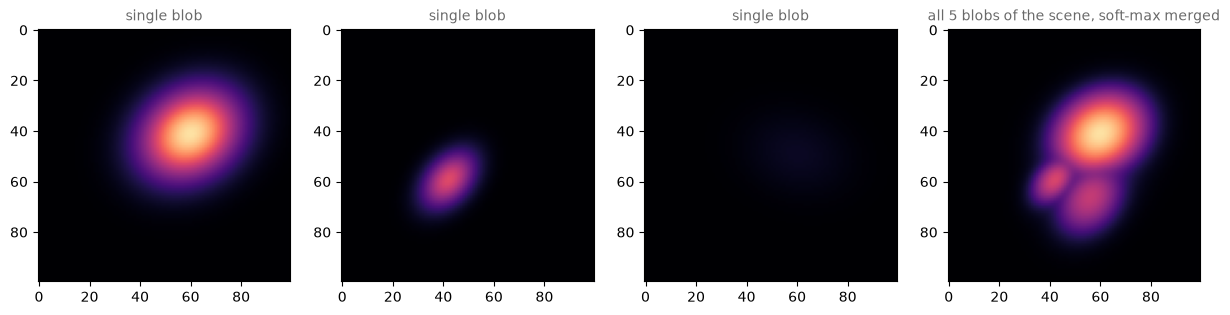

In [9]:
torch.manual_seed(0)
BS, nBlobs = 3, 5
covar_param = torch.rand(BS, nBlobs, 3)  # [s1, s2, alpha]

covar = losses.generate_covar(s1=covar_param[:, :, 0], s2=covar_param[:, :, 1], alpha=2 * torch.pi * covar_param[:, :, 2])
mean = 2 * torch.rand(BS, nBlobs, 2) - 1
strength = torch.rand(BS, nBlobs)

pdfs = losses.batched_2D_gaussian(covar, mean, strength, losses.make_grid(100, grid_lim=(-3, 3)))
merged = losses.softmaxadd_pdfs(pdfs, softmax_temp=0.1)
print(pdfs.shape, "->", merged.shape)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, blob in zip(axes, pdfs[0, :3]):
    ax.imshow(blob, cmap="magma", vmin=0, vmax=1)
    ax.set_title("single blob", fontsize=10, color="dimgray")
axes[3].imshow(merged[0], cmap="magma", vmin=0, vmax=1)
axes[3].set_title("all 5 blobs of the scene, soft-max merged", fontsize=10, color="dimgray");

### the target maps

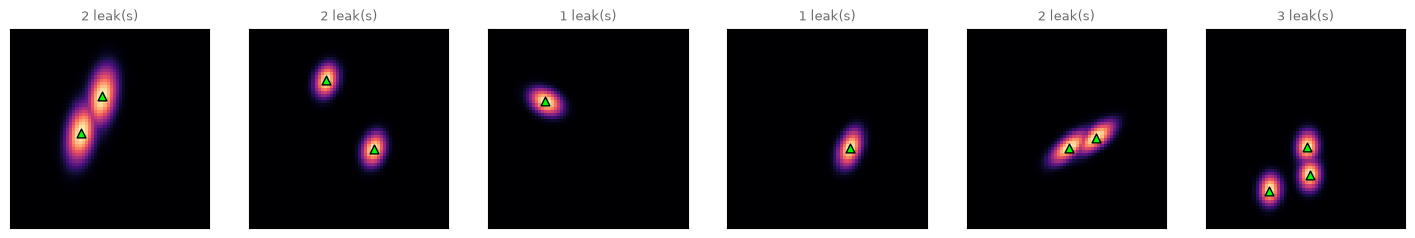

In [10]:
def show_map(ax, heatmap, el, title):
    # the maps are indexed [x, y], so transpose for imshow
    ax.imshow(np.asarray(heatmap).T, origin="lower", extent=(-1, 1, -1, 1), cmap="magma", vmin=0, vmax=1)
    ax.scatter(*el["pos_leaks"][: int(el["n_leaks"])].T, s=40, marker="^", color="lime", edgecolors="black")
    ax.set(xticks=[], yticks=[])
    ax.set_title(title, fontsize=9, color="dimgray")


examples = load_scenes("../data/multi_leak_50k.h5", 6)
targets = losses.label_heatmap(default_collate(examples), grid_res=64)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, el, target in zip(axes, examples, targets):
    show_map(ax, target, el, f"{int(el['n_leaks'])} leak(s)")

### B1 - B3: three ways to produce the map

all three are only run as **overfit tests** on a handful of scenes (8 training scenes for B1 and B2, 12 for B3), 1000 to 2000 epochs: if a model can't even memorize ten scenes, there is no point in training it on 50k.

- **B1, parametric blobs:** the network predicts strength, mean and covariance of 5 gaussians and the map is rendered from them with the functions above. compact and interpretable, the leak positions could be read off directly.
- **B2, conv decoder:** a 128-d embedding is reshaped to `[2, 8, 8]` and upsampled to 64x64 with bilinear interpolation + convolutions. most of the target is background, so foreground and background pixels are weighted to balance each other kind of.
- **B3, linear layer:** the 32x32 map directly from a linear layer, blobs made twice as big, plain RMSE. no fancy tricks, just to see if *anything* fits.

B1: parametric blobs                loss of an empty map on the training scenes: 0.1122
B1: parametric blobs                train loss: start 0.2889 -> end 0.1122 | validation: best 0.0916, end 0.0916


B2: conv decoder (weighted RMSE)    loss of an empty map on the training scenes: 0.4538
B2: conv decoder (weighted RMSE)    train loss: start 0.6226 -> end 0.1709 | validation: best 0.3426, end 0.4721


B3: linear layer                    loss of an empty map on the training scenes: 0.1418
B3: linear layer                    train loss: start 0.4829 -> end 0.0030 | validation: best 0.1363, end 0.1470


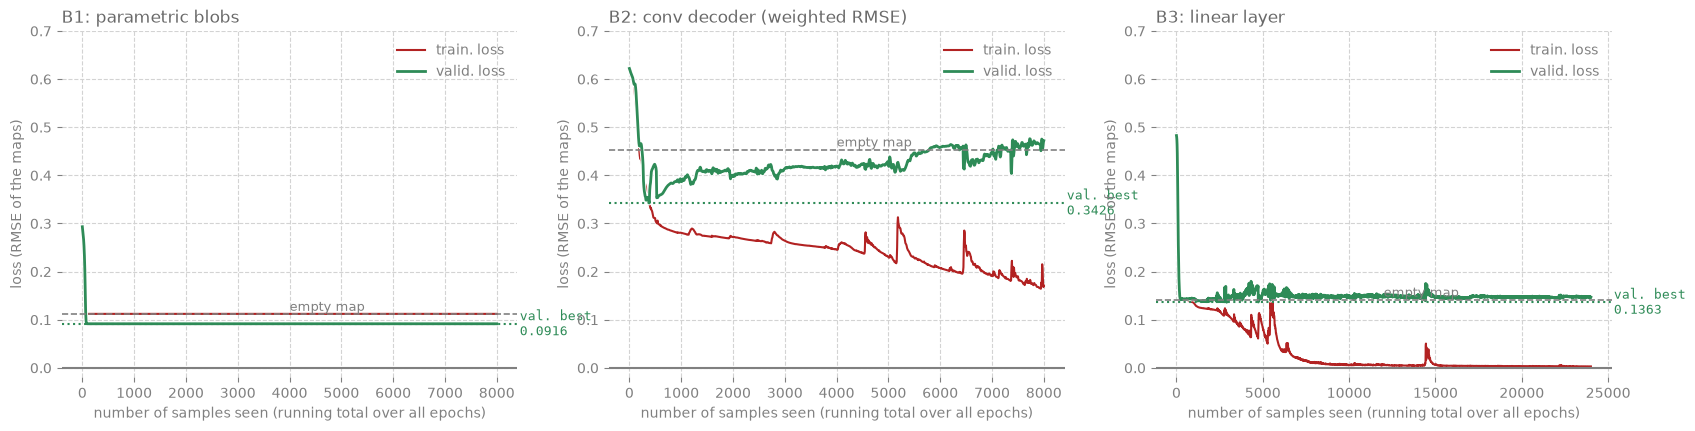

In [11]:
runs = {name: load_run(name, RESULTS) for name in ("blobs", "conv_heatmap", "linear_heatmap")}
titles = {"blobs": "B1: parametric blobs", "conv_heatmap": "B2: conv decoder (weighted RMSE)", "linear_heatmap": "B3: linear layer"}

grid_res = {"blobs": 100, "conv_heatmap": 64, "linear_heatmap": 32}
covarboost = {"blobs": 1, "conv_heatmap": 1, "linear_heatmap": 2}


def empty_map_loss(name):
    # what would the loss on the training scenes be for a map that is 0 everywhere?
    batch = default_collate(scenes_of(name)[0])
    if name == "blobs":
        target = losses.label_heatmap(batch, grid_res[name])
        return torch.sqrt((target**2).sum(dim=(1, 2)) / grid_res[name] ** 2).mean().item()
    return EXPERIMENTS[name]["criterion"](batch, torch.full((len(batch["n_leaks"]), grid_res[name], grid_res[name]), -50.0)).mean().item()


fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, (name, (_, hist)) in zip(axes, runs.items()):
    plotting.plot_history(hist, ax=ax, title=titles[name], y_range=(-0.02, 0.7), y_label="loss (RMSE of the maps)", bands=False)
    empty = empty_map_loss(name)
    ax.axhline(empty, color="gray", ls="--", lw=1.2)
    ax.annotate("empty map", xy=(0.5, empty), xycoords=("axes fraction", "data"), color="gray", va="bottom", fontsize=9)
    print(f"{titles[name]:35s} loss of an empty map on the training scenes: {empty:.4f}")
    print(f"{titles[name]:35s} train loss: start {hist['train']['loss'][0]:.4f} -> end {hist['train']['loss'][-1]:.4f} | validation: best {hist['valid_best']:.4f}, end {hist['valid']['loss'][-1]:.4f}")

target (top) vs. prediction (bottom) for training scenes, i.e. scenes that the model has seen 1000+ times:

B1, first training scene, the 5 blobs:
  strength:    [0. 0. 0. 0. 0.]
  mean (raw):  [[-2.9, -50.1], [14.7, -49.1], [14.4, -76.4], [-0.6, -2.2], [55.8, -57.4]]


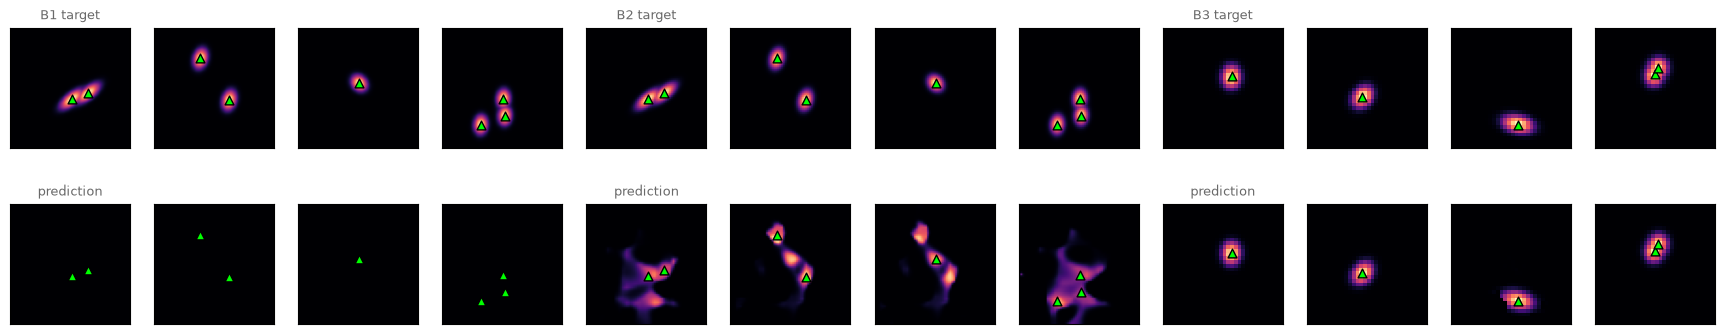

In [12]:
def predicted_maps(name, scenes):
    out = predict(runs[name][0], scenes, device)
    return losses.blob_heatmap(out) if name == "blobs" else torch.sigmoid(out)


fig, axes = plt.subplots(2, 12, figsize=(22, 4.2))
for block, name in enumerate(runs):
    train_scenes, _ = scenes_of(name)
    train_scenes = train_scenes[:4]
    target = losses.label_heatmap(default_collate(train_scenes), grid_res[name], covarboost[name])
    prediction = predicted_maps(name, train_scenes)
    for k, el in enumerate(train_scenes):
        show_map(axes[0, 4 * block + k], target[k], el, titles[name][:2] + " target" if k == 0 else "")
        show_map(axes[1, 4 * block + k], prediction[k], el, "prediction" if k == 0 else "")

blob_out = predict(runs["blobs"][0], scenes_of("blobs")[0], device)
print("B1, first training scene, the 5 blobs:")
print("  strength:   ", torch.sigmoid(blob_out[0, :, 0]).numpy().round(4))
print("  mean (raw): ", [[round(float(v), 1) for v in mean] for mean in blob_out[0, :, 1:3]])

for B3 some optimizer statistics are logged per step, to see whether the training is stuck or just slow:

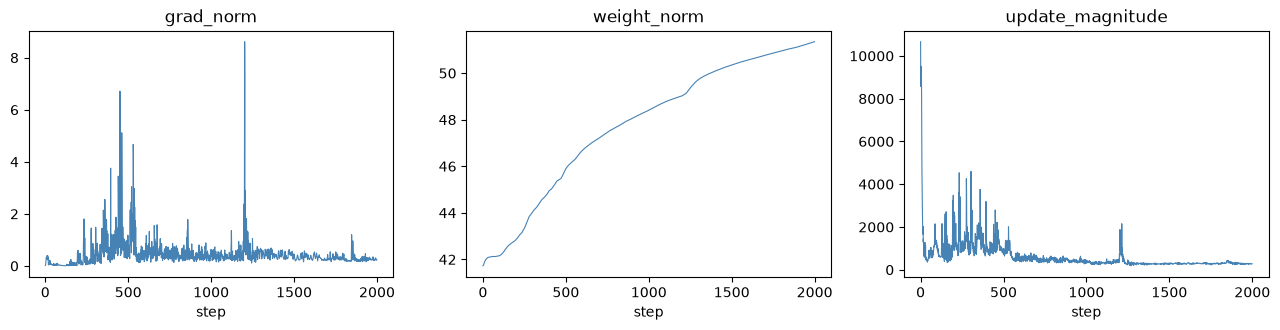

In [13]:
diag = runs["linear_heatmap"][1]["diagnostics"]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
for ax, key in zip(axes, ("grad_norm", "weight_norm", "update_magnitude")):
    ax.plot(diag[key], color="steelblue", lw=0.8)
    ax.set(xlabel="step", title=key)

the gray dashed line in the loss plots is the loss of a map that is **zero everywhere**. it explains most of what happens here: the targets are a few small blobs on an empty background, so an empty map is already a decent answer for a plain RMSE, and every model first runs towards it.

- **B1 (parametric blobs) gets stuck there for good.** within the first ten steps the loss drops exactly onto the empty-map value and never moves again. the printed parameters show how: all strengths are 0 and most of the means have run off to coordinates like 50, far outside the site, where they are clamped and get no gradient at all. switching the blobs off is the fastest way to reduce the loss, and once a blob is off (or outside) nothing pulls it back. so this one isn't even able to overfit a small dataset!
- **B2 (conv decoder) is slow, not stuck.** the class weighting does what it's built for, an empty map is expensive here (0.45). the loss is still going down after 1000 steps and the predictions are blurry blobs in roughly the right places plus some ghosts. 1000 steps are not enough to tell.
- **B3 (linear layer) overfits perfectly**, given time. it sits near the empty-map plateau for the first 250 steps or so and then memorizes all 12 maps (loss 0.003). stopping it early would have looked like a failure too. the optimizer statistics above tell the same story: gradient norm is tiny on the plateau (around 0.02) and more than ten times larger once the model starts to draw blobs.

the validation curves say nothing in any of the three, nobody generalizes from 8 scenes. the actual question, whether a heatmap head learns something from 50k scenes, is still open. B2 and B3 suggest that it's worth a try.

### prototype: getting leaks back out of a map (soft NMS)

a heatmap is not the final answer, the leak positions still have to be extracted from it. the plan is a differentiable non-maximum suppression: slide a window over the map, take a softmax inside every window and keep the weight of the center pixel. that value is close to 1 only where the center is the maximum of its window. not used in a model yet, the maps are not good enough to need it.

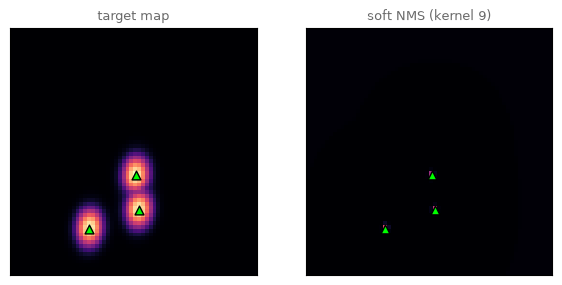

In [14]:
def nms_vec_2d(data: np.ndarray, kernel_sz: int, softmax_temp: float = 0.1, pad_mode: str = "edge"):
    padded_data = np.pad(data, ((kernel_sz // 2, kernel_sz // 2), (kernel_sz // 2, kernel_sz // 2)), mode=pad_mode)

    # extract sliding windows using as_strided
    shape = (data.shape[0], data.shape[1], kernel_sz, kernel_sz)
    strides = (padded_data.strides[0], padded_data.strides[1], padded_data.strides[0], padded_data.strides[1])
    sliding_windows = np.lib.stride_tricks.as_strided(padded_data, shape=shape, strides=strides)
    windows_flat = sliding_windows.reshape(sliding_windows.shape[0], sliding_windows.shape[1], -1)

    # apply softmax across each window (temperature relative to the spread inside the window)
    modified_temp = softmax_temp * np.std(windows_flat, axis=-1)[:, :, None] + 1e-12
    soft_maximums = scipy.special.softmax(windows_flat / modified_temp, axis=2)

    # take the center value (middle index of each softmax window)
    return soft_maximums[:, :, (kernel_sz**2) // 2]


three_leaks = next(i for i, el in enumerate(examples) if int(el["n_leaks"]) == max(int(e["n_leaks"]) for e in examples))
target = np.ascontiguousarray(targets[three_leaks].numpy())

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
show_map(axes[0], target, examples[three_leaks], "target map")
show_map(axes[1], nms_vec_2d(target, kernel_sz=9), examples[three_leaks], "soft NMS (kernel 9)")

## C. sanity check: can it at least count?

with the confidences of A broken and the heatmaps struggling on a handful of scenes, one step back: sanity check to see if even ANYTHING can be learned from the multi-leak data. just one number is predicted and the loss is the absolute value of the difference between the prediction and the true nr_leaks. 1000 scenes with 1-3 leaks (800 / 200).

train loss at the end 0.096 | best validation loss 0.264
always predicting the median (2 leaks) would give: 0.685
validation scenes where the rounded prediction is correct: 0.700


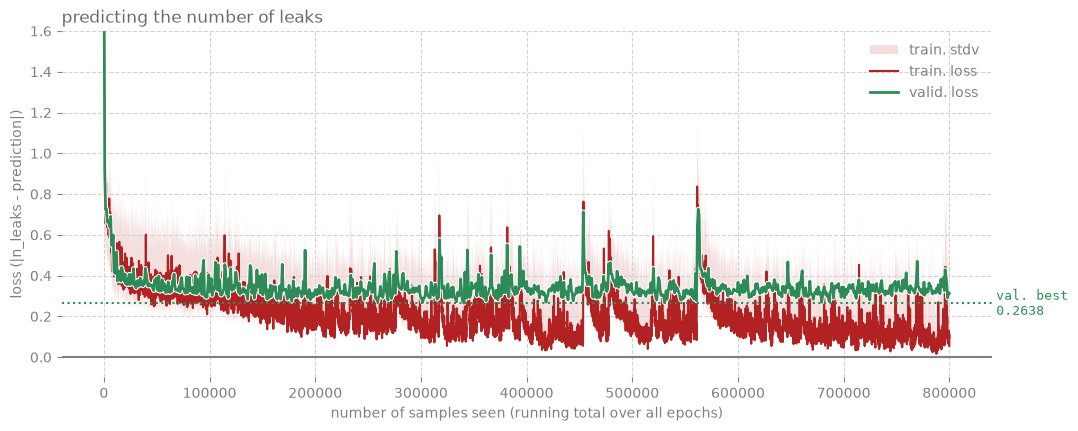

In [15]:
model_count, history_count = load_run("count", RESULTS)

fig, ax = plt.subplots(figsize=(12, 4.5))
plotting.plot_history(history_count, ax=ax, title="predicting the number of leaks", y_range=(-0.1, 1.6), y_label="loss (|n_leaks - prediction|)", smooth=5)

_, valid_count = scenes_of("count")
n_true_count = np.array([int(el["n_leaks"]) for el in valid_count])
n_pred_count = predict(model_count, valid_count, device).numpy()

print(f"train loss at the end {np.mean(history_count['train']['loss'][-25:]):.3f} | best validation loss {history_count['valid_best']:.3f}")
print(f"always predicting the median (2 leaks) would give: {np.abs(n_true_count - 2).mean():.3f}")
print(f"validation scenes where the rounded prediction is correct: {np.mean(np.round(n_pred_count) == n_true_count):.3f}")

the network **can** count to some degree: it fits the 800 training scenes and gets 70% of the validation scenes right, where always guessing would give 33%. it also overfits clearly with so little data. so the answer to "can anything be learned from the multi-leak data" is yes, and the problems in A and B are in the losses and not in the encoder.

## where this leaves things

| | result |
|---|---|
| A, slots + sinkhorn | positions reasonable (0.13 from the matched leak), confidences broken: never predicts fewer than two leaks |
| B1, parametric blobs | collapses to an empty map within ten steps and stays there |
| B2, conv decoder | fits slowly, test is too short to say more |
| B3, linear layer | memorizes the training maps, after a plateau at the empty map |
| C, counting | learnable (70% correct from 800 scenes) |

nothing in phase 2 works yet, but none of the approaches is shown to fail on the actual task either. A locates leaks and needs a confidence loss that can't saturate (and the right penalty constant). B1 is stuck in a trap that has a known fix (focal loss instead of RMSE), B2 and B3 need a run on the full dataset instead of an overfit test. what I would do next for each of them is in the README.